In [119]:
import torch
import matplotlib.pyplot as plt
from torch import nn

print(torch.__version__)


2.14.1+cu130


In [120]:
# Pytorch workflow

what_were_covering = {1: "data (prepare and load)",
                      2: "build model",
                      3: "fitting the model to data (training)",
                      4: "making predictions and evaluating a model (inference)",
                      5: "saving and loading a model",
                      6: "putting it all together"}
what_were_covering

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating a model (inference)',
 5: 'saving and loading a model',
 6: 'putting it all together'}

In [121]:
#  1. Data (preparing and loading)

# Can be almost anything:
#   a. excel spreadsheet
#   b. images of any kind
#   c. videos
#   d. audios

# Machine learning is about: 
#   (a) converting data into numerical representations
#   (b) build a model to learn patterns in that numerical representation

# We'll use a linear regression formula to make a straight line with known parameters

In [122]:
# Create known parameter
weight = 0.7
bias = 0.3

# Create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

print(X[:10], y[:10])
print(len(X), len(y))

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]]) tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])
50 50


In [123]:
# splitting data into training and test sets (important)

# We have:
#   1. a training set (~60-80%) always
#   2. validation set (tune model patterns) (~10-20%) often, but not always
#   3. test set (see if model is ready for the wild) (~10-20%) always

train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

print(len(X_train), len(y_train), len(X_test), len(y_test))

40 40 10 10


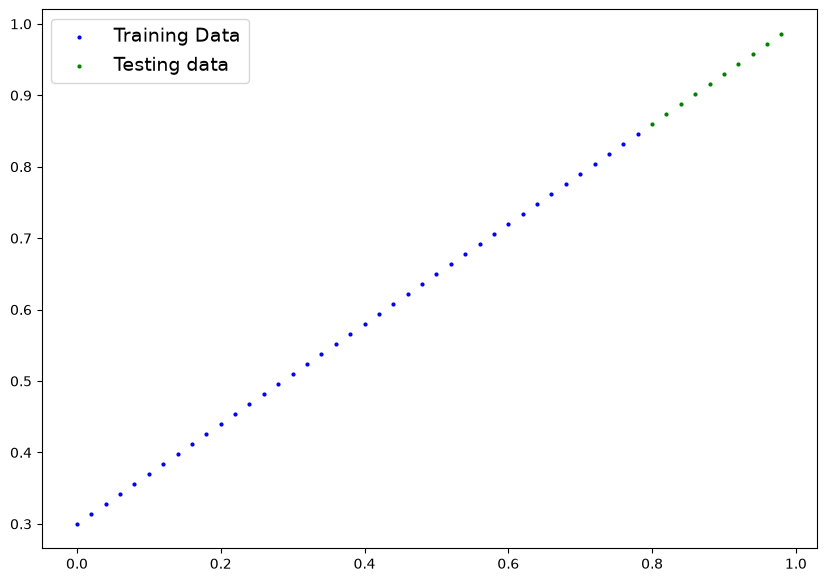

In [124]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
    """
    Plots training data, test data and compares predictions
    """

    plt.figure(figsize=(10, 7))
    plt.scatter(train_data, train_labels, c="b", s=4, label="Training Data")
    plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

    if predictions is not None:
        plt.scatter(test_data, predictions, c="r", s=4, label="Predications")

    plt.legend(prop={"size": 14})
plot_predictions()


In [125]:
# Building the model

class LinearRegressionModel(nn.Module): # Almost everything in Pytorch inherits nn.Module
    def __init__(self):
        super().__init__()

        # initialize parameters
        self.weights = nn.Parameter(
            torch.randn(
                1,                      # start with a random weight and try to adjust it to the ideal weight 
                requires_grad=True,     # can this parameter be updated via gradient descent? 
                dtype=torch.float       # PyTorch loves the datatype torch.float32
            )
        )
        self.bias = nn.Parameter(
            torch.randn(
                1, 
                requires_grad=True, 
                dtype=torch.float
            )
        )

    #  forward method to define the computation in the model
    def forward(self, x: torch.Tensor) -> torch.Tensor: # "x" is the input data
        return self.weights * x + self.bias

In [126]:
# What our model does
# 1. Start iwth random values (weight and bias)
# 2. Look at training data and adjust the reandom values to better represent (or get closer to) the
#    ideal values we used to created the data

# Two main algorithms:
#   1. Gradient descent
#   2. Backpropagation

In [127]:
# Pytorch model building essentials

# torch.nn - Contains all of the building blocks for computational graphs
# torch.nn.Parameter - What parameters should our model try and learn from
# torch.nn.Module - The base class flor all neural network modules
# torch.optim - Where the optimizers in Pytorch live. They help with gradient descent
# def forward - all nn.Module classes have this. It defines what happens in the forward computation

In [128]:
# Checking the contents of our PyTorch model

torch.manual_seed(42)
model_0 = LinearRegressionModel()

print(model_0)
list(model_0.parameters())
print(model_0.state_dict())

LinearRegressionModel()
OrderedDict({'weights': tensor([0.3367]), 'bias': tensor([0.1288])})


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])
tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])


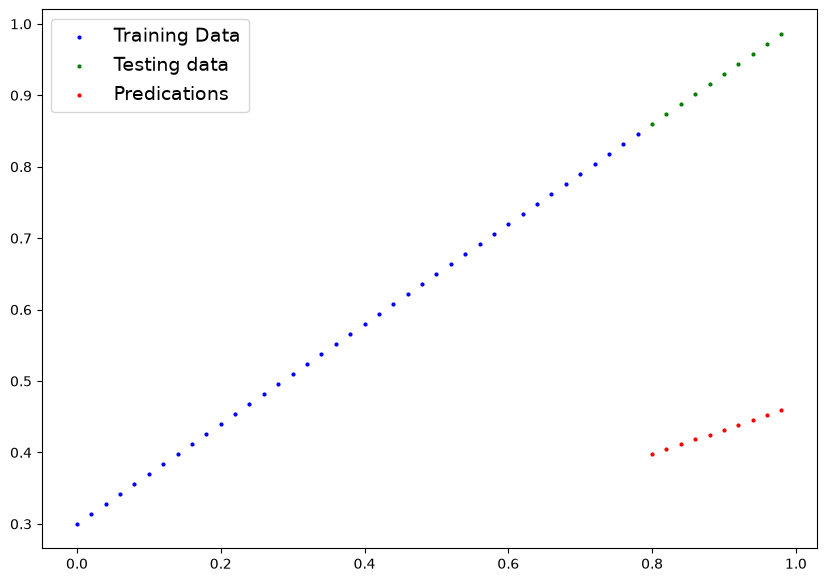

In [129]:
# Using `torch.inference_mode()` to see our model's predictive power

# print(model_0(X_test)) # Without inference mode

# inference is when you make prediction
with torch.inference_mode():
    y_preds = model_0(X_test)

print(y_preds)
print(y_test)

# Without using inference mode, we don't turn off the gradient tracking. 
# It disables it so that Pytorch doesn't keep track of stuff and makes it faster
# You can do a similar one with torch.no_grad(), but inference mode is prefered
plot_predictions(predictions=y_preds)

In [130]:
# The whole point of traning is to move a model from unknown parameters (often random)
# to some known parameters

# We need to measure how poor our model's predictions are. We use a loss function for this

# Things we need to train
#   Loss function - A function to measure how wrong your model's predictions are to the ideal outputs
#   Optimizer - Takes into account the loss of a model and adjusts the model's parameters to improve the loss function

# For Pytorch, we need:
#   A training loop
#   A testing loop

# We will use MAE_loss = torch.nn.L1Loss() as our loss function (Mean absolute error)

In [131]:
# Setup a loss function

loss_fn = nn.L1Loss()
print(loss_fn)

# Setup an optimizer
optimizer = torch.optim.SGD(
    params=model_0.parameters(),
    lr=0.01                     # learning rate - possibly the most important learning hyperparamter (that you can set)
                                # Larger means bigger jump on parameter, smaller means smaller jump on parameter
) 

# We set hyperparameters, model sets parameters

L1Loss()


In [132]:
# Building a training loop (and testing loop) in Pytorch

# A couple of things we need:
#   0. Loop through the data
#   1. forward pass (this involves data moving through our model's `forward()` function(s) to make predictions on data) AKA forward propagation
#   2. Calculate the loss (compare forward pass predictions to ground truth labels)
#   3. Optimizer zero grad
#   4. Loss  backwards - move backwards throguh the network to calculate the gradients of each paramters of our models with respect to the loss
#   5. Optimizer step - use the optimizer to adjust our model's parameters to try and improve the loss
torch.manual_seed(42)
epochs = 200 # an epoch is 1 loop through the data (hyperparameter)

# Track different values
epoch_count = []
loss_values = []
test_loss_values = []

# 0. Loop through the data
for epoch in range(epochs):
    
    # Training
    model_0.train() # Set model to training mode (sets all parameters that require gradients to require gradients)

    y_pred = model_0(X_train) # 1. Forward pass

    loss = loss_fn(y_pred, y_train) # 2. Calculate loss

    optimizer.zero_grad() # 3 Optimizer zero grad

    loss.backward() # 4. Perform backpropagation

    optimizer.step() # 5. Perform gradient descent

    # Testing
    model_0.eval() # Turns off gradient tracking and other stuff not neede for testing


    # Turns off gradient tracking and more thinks behind the scenes
    with torch.inference_mode():
        test_pred = model_0(X_test) # 1. Do the forward pass

        test_loss = loss_fn(test_pred, y_test) # 2. Calculate the loss

    # Print out what's happening
    if epoch % 10 == 0:
        epoch_count.append(epoch)
        loss_values.append(loss)
        test_loss_values.append(test_loss)
        
        print(f"Epoch: {epoch} | Test: {loss} | Test Loss: {test_loss}") 
        print(model_0.state_dict())

Epoch: 0 | Test: 0.31288138031959534 | Test Loss: 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Epoch: 10 | Test: 0.1976713240146637 | Test Loss: 0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
Epoch: 20 | Test: 0.08908725529909134 | Test Loss: 0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
Epoch: 30 | Test: 0.053148526698350906 | Test Loss: 0.14464017748832703
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768])})
Epoch: 40 | Test: 0.04543796554207802 | Test Loss: 0.11360953003168106
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868])})
Epoch: 50 | Test: 0.04167863354086876 | Test Loss: 0.09919948130846024
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
Epoch: 60 | Test: 0.03818932920694351 | Test Loss: 0.08886633068323135
OrderedDict({'weights': tensor([0.5116]), 'bias': tensor([0.3788])})
Epoch: 70 | Test: 0.03

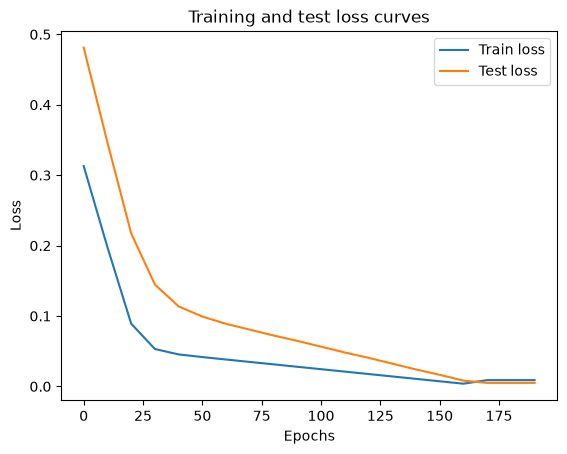

In [133]:
import numpy as np
plt.plot(epoch_count, np.array(torch.tensor(loss_values).numpy()), label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

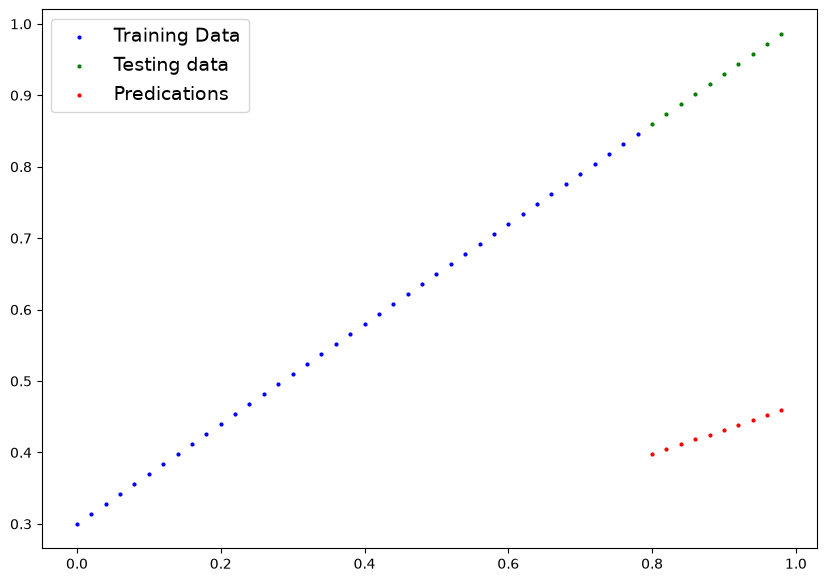

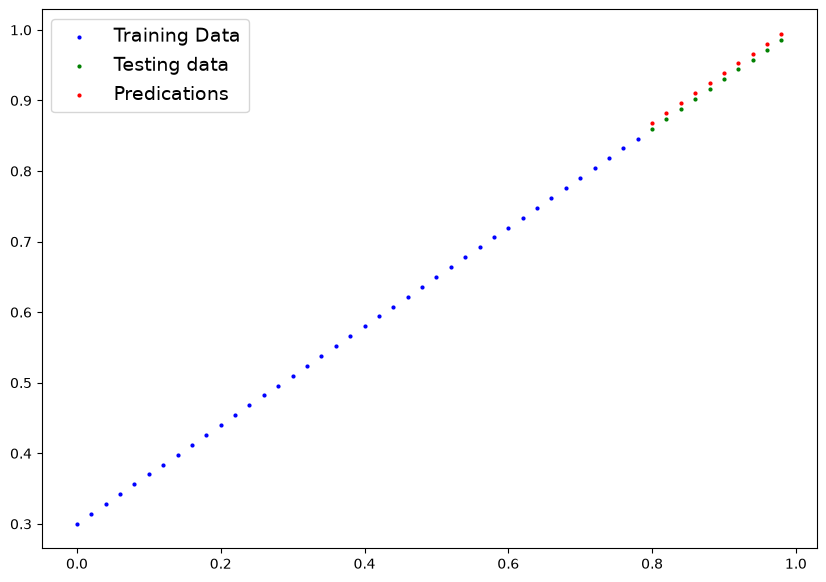

In [134]:
with torch.inference_mode():
    y_preds_new = model_0(X_test)

# Original predictions
plot_predictions(predictions=y_preds)

# Predictions after training and testing loop
plot_predictions(predictions=y_preds_new)

In [ ]:
# Saving a model

# Three main methods for saving and loading models in Pytorch
#   1. `torch.save()` - allows you to save pytorch object in python's pickle format
#   2. `torch.load()` - allows you to load a pytorch object
#   3. `torch.nn.Module.load_state_dict()` - this allows to load a model's saved dictionary state

from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create a model save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth" # .pth is a the convention for pytorch
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

print(MODEL_SAVE_PATH)

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(
    obj=model_0.state_dict(),
    f=MODEL_SAVE_PATH
)

models\01_pytorch_workflow_model_0.pth
Saving model to: models\01_pytorch_workflow_model_0.pth


In [141]:
# Loading a pytorch model

# Since we saved our model's `state_dict()`, we will create a new isntance of our model class and load the saved `state_dict()` into that

loaded_model_0 = LinearRegressionModel()
print(loaded_model_0.state_dict())

loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
print(loaded_model_0.state_dict())

OrderedDict({'weights': tensor([2.2082]), 'bias': tensor([-0.6380])})
OrderedDict({'weights': tensor([0.6990]), 'bias': tensor([0.3093])})


In [143]:
# Make some predictions with our loaded model and compare to original model

loaded_model_0.eval()

with torch.inference_mode():
    loaded_model_preds = loaded_model_0(X_test)

model_0.eval()
with torch.inference_mode():
    y_preds = model_0(X_test)

print(loaded_model_preds == y_preds)

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])


2.14.1+cu130
cuda
tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]]) tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])
40 40 10 10
LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
) OrderedDict({'linear_layer.weight': tensor([[0.7645]]), 'linear_layer.bias': tensor([0.8300])})
cpu
cuda:0
Epoch: 0 | Loss: 0.5551779270172119 | Test Loss: 0.5739762187004089
Epoch: 10 | Loss: 0.4399681091308594 | Test Loss: 0.4392664134502411
Epoch: 20 | Loss: 0.3247582018375397 | Test Loss: 0.30455657839775085
Epoch: 30 | Loss: 0.20954833924770355 | Test Loss: 0.16984669864177704
Epoch: 40 | Loss: 0.09433844685554504 | Test Loss: 0.03513690456748009
Epoch: 50 | Loss: 0.023886388167738914 | Test Loss: 0.0478

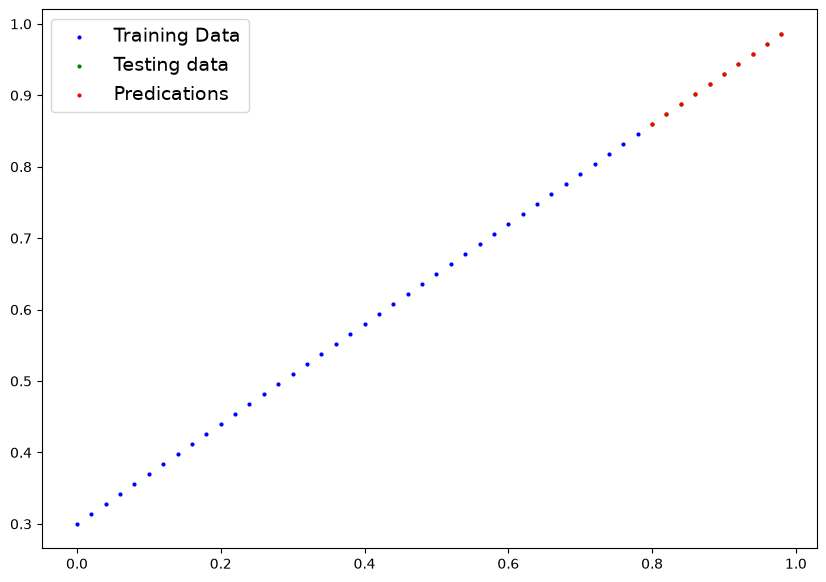

In [166]:
# 6 Putting it all together

import torch
from torch import nn
import matplotlib.pyplot as plt

print(torch.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

# 6.1 Create some data using the linear regression formula of y = mx + b

weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias
print(X[:10], y[:10])

train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
print(len(X_train), len(y_train), len(X_test), len(y_test))

# plot_predictions(X_train, y_train, X_test, y_test)

# 6.2 Building a pytorch linear model

class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()

        # use nn.Linear() for creating the model parameters (1x to 1y)
        self.linear_layer = nn.Linear(
            in_features=1,
            out_features=1
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
print(model_1, model_1.state_dict())

print(next(model_1.parameters()).device)
model_1.to(device)
print(next(model_1.parameters()).device)

# 6.3 Training

loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)

torch.manual_seed(42)

epochs = 200

X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
    model_1.train()
    
    y_pred = model_1(X_train)
    loss = loss_fn(y_pred, y_train)

    optimizer.zero_grad()
    
    loss.backward()
    optimizer.step()

    model_1.eval()
    with torch.inference_mode():
        test_pred = model_1(X_test)
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")

print(model_1.state_dict())

# 6.4 Making and evaluating predictions

model_1.eval()

with torch.inference_mode():
    y_preds = model_1(X_test)

print(y_preds)

plot_predictions(predictions=y_preds.cpu())

from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

print(f"Saving model to {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(), f=MODEL_SAVE_PATH)